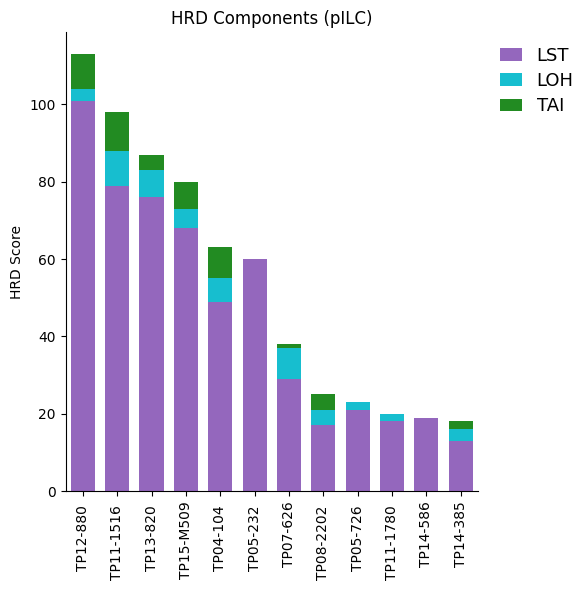

Saved: /ix1/alee/LO_LAB/Personal/Rahul/pILC/Bionano/HRD/HRD_pILC_only.png


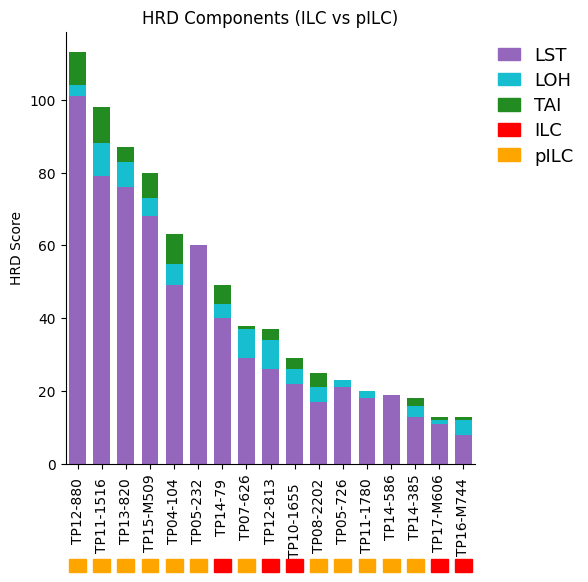

Saved: /ix1/alee/LO_LAB/Personal/Rahul/pILC/Bionano/HRD/HRD_ILC_pILC.png


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from matplotlib.patches import Patch

# =========================
# Load data
# =========================
df = pd.read_csv("/ix1/alee/LO_LAB/Personal/Rahul/pILC/Bionano/HRD/pILC_HRD.csv")

# HRD component colors
color_lst = "#9467bd"
color_loh = "#17becf"
color_tai = "#228B22"

# Histology colors
histology_colors = {
    "ILC": "#FF0000",
    "pILC": "#FFA500"
}

# Output directory
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/pILC/Bionano/HRD"
os.makedirs(OUTDIR, exist_ok=True)


# =========================
# Plot function
# =========================
def plot_hrd(df_plot, title, outfile, annotate_histology=False):

    df_plot = df_plot.sort_values("Total", ascending=False).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(6,6))

    x = range(len(df_plot))

    # ---- Use ONE bar width everywhere
    bar_w = 0.7

    # ---- Stacked bars
    ax.bar(x, df_plot["LST"], width=bar_w, color=color_lst, label="LST")
    ax.bar(x, df_plot["LOH"], width=bar_w, bottom=df_plot["LST"], color=color_loh, label="LOH")
    ax.bar(
        x,
        df_plot["TAI"],
        width=bar_w,
        bottom=df_plot["LST"] + df_plot["LOH"],
        color=color_tai,
        label="TAI"
    )

    # ---- X limits (controls gap at left/right)
    ax.set_xlim(-0.50, len(df_plot) - 0.5)

    # ---- X ticks
    ax.set_xticks(list(x))
    ax.set_xticklabels(df_plot["Sample"], rotation=90)

    ax.set_ylabel("HRD Score")
    ax.set_title(title)

    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

    # =========================
    # Histology annotation bar
    # =========================
    if annotate_histology:

        bar_h = 0.03
        y0 = -0.25  # move up/down the annotation strip

        for i, row in df_plot.iterrows():
            ax.add_patch(plt.Rectangle(
                (i - bar_w/2, y0),
                bar_w,
                bar_h,
                transform=ax.get_xaxis_transform(),
                color=histology_colors.get(row["Histology"], "grey"),
                clip_on=False
            ))

        hist_legend = [
            Patch(color=histology_colors["ILC"], label="ILC"),
            Patch(color=histology_colors["pILC"], label="pILC")
        ]

        ax.legend(
            handles=[
                Patch(color=color_lst, label="LST"),
                Patch(color=color_loh, label="LOH"),
                Patch(color=color_tai, label="TAI")
            ] + hist_legend,
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
            fontsize=13,
            title_fontsize=14,
            frameon=False,
            labelspacing=0.4,
            handlelength=1.2,
            borderpad=0.3
        )

    else:
        ax.legend(
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
            fontsize=13,
            title_fontsize=14,
            frameon=False,
            labelspacing=0.4,
            handlelength=1.2,
            borderpad=0.3
        )

    plt.tight_layout()
    plt.savefig(outfile, dpi=300)
    plt.show()

    print("Saved:", outfile)

# =========================
# pILC only
# =========================
df_pilc = df[df["Histology"]=="pILC"]

plot_hrd(
    df_pilc,
    "HRD Components (pILC)",
    os.path.join(OUTDIR,"HRD_pILC_only.png"),
    annotate_histology=False
)


# =========================
# ILC + pILC
# =========================
df_both = df[df["Histology"].isin(["ILC","pILC"])]

plot_hrd(
    df_both,
    "HRD Components (ILC vs pILC)",
    os.path.join(OUTDIR,"HRD_ILC_pILC.png"),
    annotate_histology=True
)